This notebook accompanies [16-differentiable-simulation](https://xing-phys.github.io/ai-for-physics/16-differentiable-simulation.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Differentiable simulation and learned mechanics 

::: {.callout-note}
## The physical question
How can we adjust a force law, material parameter, or control field using the final outcome of a simulation, while keeping track of numerical error and physical structure?

You will derive forward sensitivities and discrete adjoints, compare continuous and discrete differentiation, learn how implicit solves are differentiated, and distinguish Hamiltonian model structure from the properties of the time integrator used to simulate it.
:::

## A simulation can be part of an experiment

An unknown spring constant affects an oscillator's trajectory. An unknown viscosity affects a flow field. A laser pulse affects the final state of an atom. In all three cases a simulator maps adjustable parameters to observable outcomes. If that mapping is differentiable, its derivative indicates how to change the parameters to reduce disagreement with data or improve an experimental objective.

Let $y(t)\in\mathbb R^d$ be a physical state and $\theta\in\mathbb R^p$ parameters. Consider

$$
\dot y=f(y,t,\theta),\qquad y(0)=y_0(\theta),
\qquad \mathcal J(\theta)=\Phi(y(T),\theta).
$$ 

The parameters may be ordinary physical constants, coefficients of a control pulse, or weights in a neural constitutive relation. **Differentiable simulation** means that gradients of the objective are computed through the numerical solution process or through mathematically equivalent sensitivity equations. It does not imply that the simulator is correct, that its gradients are well conditioned, or that the inverse problem has a unique solution.

A **computational graph** records elementary operations and their dependencies. A time step is a small graph; a rollout is their composition. Automatic differentiation applies the chain rule to this graph. It differs from finite differences, which perturb a parameter and rerun the whole calculation, and from symbolic differentiation, which seeks a simplified closed-form expression. Derivatives are evaluated numerically along the actual calculation.

## Forward sensitivities: follow each parameter

Define the sensitivity matrix $S(t)=\partial y(t)/\partial\theta$, a $d\times p$ array. Differentiate the ODE with respect to $\theta$:

$$
\dot S=f_yS+f_\theta,\qquad
S(0)=\partial_\theta y_0,
\qquad
\nabla_\theta\mathcal J=\Phi_\theta+S(T)^T\nabla_y\Phi.
$$

Here $(f_y)_{ij}=\partial f_i/\partial y_j$ and $(f_\theta)_{ia}=\partial f_i/\partial\theta_a$. To see the first equation componentwise, differentiate $f_i(y(\theta),t,\theta)$: changing parameter $\theta_a$ changes $f_i$ directly and changes every state component $y_j$, giving
$\dot S_{ia}=\sum_j(\partial f_i/\partial y_j)S_{ja}+\partial f_i/\partial\theta_a$.

Forward sensitivities are attractive when there are few parameters and many desired outputs. With millions of network weights, storing and propagating a column for every parameter is impractical. Reverse-mode differentiation instead follows the sensitivity of a scalar objective backward.

## Deriving the discrete adjoint

Write a numerical solver as steps
$y_{n+1}=\Psi_n(y_n,\theta)$ for $n=0,\ldots,N-1$. For now let
$\mathcal J=\Phi(y_N,\theta)$. A perturbation obeys

$$
\delta y_{n+1}=A_n\delta y_n+B_n\delta\theta,
\qquad A_n=\frac{\partial\Psi_n}{\partial y_n},\quad
B_n=\frac{\partial\Psi_n}{\partial\theta}.
$$

Start with $\delta\mathcal J=(\nabla_y\Phi)^T\delta y_N+\Phi_\theta^T\delta\theta$. Set $\lambda_N=\nabla_y\Phi$. Substitute the final time-step perturbation:
$\lambda_N^T\delta y_N=\lambda_N^TA_{N-1}\delta y_{N-1}+\lambda_N^TB_{N-1}\delta\theta$.
The coefficient of $\delta y_{N-1}$ is $A_{N-1}^T\lambda_N$. Repeat this substitution backward to obtain

$$
\lambda_n=A_n^T\lambda_{n+1},\qquad
\nabla_\theta\mathcal J=\Phi_\theta+
\sum_{n=0}^{N-1}B_n^T\lambda_{n+1}
+(\partial_\theta y_0)^T\lambda_0.
$$ 

The adjoint $\lambda_n$ has the size of the state, regardless of parameter count. Products with Jacobians can be computed without explicitly assembling the full matrices. This is why reverse-mode differentiation is efficient for a scalar loss and many parameters.

If the objective includes measurements at intermediate times,
$\mathcal J=\Phi(y_N,\theta)+\sum_n\ell_n(y_n,\theta)$, the recursion becomes
$\lambda_n=A_n^T\lambda_{n+1}+\nabla_y\ell_n$, and explicit parameter derivatives of $\ell_n$ are added to the gradient. The observation residual at each time injects a new adjoint contribution. Omitting these terms differentiates the wrong objective.

For explicit Euler, $\Psi_n=y_n+h f(y_n,t_n,\theta)$, so $A_n=I+hf_y$ and $B_n=hf_\theta$. Higher-order or implicit solvers have different step Jacobians. The adjoint must correspond to the solver actually used.

### Worked example: infer a relaxation rate

Take $\dot y=-ky$, $y_0=1$, and a terminal target $y_*$. The exact solution is $y(T)=e^{-kT}$, but an Euler simulation gives $y_N=(1-hk)^N$. For $\mathcal J=\tfrac12(y_N-y_*)^2$, the discrete adjoint obeys
$\lambda_N=y_N-y_*$, $\lambda_n=(1-hk)\lambda_{n+1}$, and
$\partial_k\mathcal J=-h\sum_n\lambda_{n+1}y_n$.
The derivative of the closed-form discrete solution is
$-Nh(1-hk)^{N-1}$, providing an independent exact check of the implementation.

In [1]:
import numpy as np

dt, steps, target = 0.01, 100, 0.4

def objective_gradient(rate):
    y = np.empty(steps + 1)
    y[0] = 1.0
    for n in range(steps):
        y[n+1] = y[n] * (1 - dt*rate)
    adjoint = y[-1] - target
    gradient = 0.0
    for n in range(steps-1, -1, -1):
        gradient += -dt * y[n] * adjoint
        adjoint *= 1 - dt*rate
    return 0.5*(y[-1]-target)**2, gradient

rate = 0.7
loss, grad = objective_gradient(rate)
eps = 1e-5
finite_difference = (objective_gradient(rate+eps)[0]
                     - objective_gradient(rate-eps)[0])/(2*eps)
yn = (1-dt*rate)**steps
analytic = (yn-target)*(-steps*dt*(1-dt*rate)**(steps-1))
assert np.isclose(grad, finite_difference, rtol=1e-8)
assert np.isclose(grad, analytic, rtol=1e-12)
for _ in range(120):
    _, grad = objective_gradient(rate)
    rate -= 0.8*grad
assert objective_gradient(rate)[0] < 1e-10
print("Inferred discrete rate:", round(rate, 8))
print("Continuous rate:", round(-np.log(target)/(steps*dt), 8))

Inferred discrete rate: 0.91210557
Continuous rate: 0.91629073


The fitted discrete rate is $[1-y_*^{1/N}]/h$, while the continuous rate is $-\log(y_*)/T$. They approach one another as $h\to0$. A perfect discrete fit at finite $h$ can therefore absorb integration error into the inferred physics. Repeat the inference with smaller time steps before interpreting the parameter.

## Continuous adjoints and numerical consistency

For the continuous terminal objective, let the perturbation satisfy
$\delta\dot y=f_y\delta y+f_\theta\delta\theta$. Choose an adjoint satisfying
$\dot\lambda=-f_y^T\lambda$, with $\lambda(T)=\nabla_y\Phi$. Then

$$
\frac{d}{dt}(\lambda^T\delta y)
=\dot\lambda^T\delta y+\lambda^T\delta\dot y
=\lambda^Tf_\theta\delta\theta.
$$

Integrating and adding the explicit parameter dependence gives

$$
\nabla_\theta\mathcal J=\Phi_\theta+
(\partial_\theta y_0)^T\lambda(0)+
\int_0^Tf_\theta^T\lambda\,dt.
$$ 

This is a calculus identity for sufficiently regular ODE solutions. Numerically integrating it is called **differentiate then discretize**. Differentiating the numerical steps is **discretize then differentiate**. At nonzero step size their gradients need not coincide. Adaptive step choices, interpolation, events, and solver tolerances add further differences. A finite-difference gradient check should compare against the same numerical objective, and it should use several perturbation sizes to identify a range before cancellation or truncation dominates.

Neural ODEs popularized using neural vector fields within this framework [@p-chen2018]. Reconstructing a forward trajectory by solving backward can save storage in idealized cases, but it is not universally stable. For the decay equation, backward evolution exponentially amplifies tiny reconstruction errors. Work on accurate neural-ODE adjoints emphasized numerical consistency and checkpointing [@p-gholami2019]. “Constant memory” should therefore be treated as an implementation and reconstruction assumption, not an unconditional property of differentiable integration.

## Implicit differentiation: differentiate the solution condition

Many physics codes solve a system $R(y,\theta)=0$ rather than an explicit formula. Differentiating gives
$R_y\,dy/d\theta+R_\theta=0$. If $R_y$ is invertible,
$dy/d\theta=-R_y^{-1}R_\theta$. One should generally solve a linear system rather than form this inverse.

For a scalar loss $\Phi(y,\theta)$, solve the adjoint system
$R_y^T\lambda=\nabla_y\Phi$. Then

$$
\nabla_\theta\mathcal J=\Phi_\theta-R_\theta^T\lambda.
$$ 

For $A(\theta)y=b(\theta)$, the residual is $Ay-b$ and the formula becomes
$\partial_\theta\mathcal J=\Phi_\theta+\lambda^T[\partial_\theta b-(\partial_\theta A)y]$, with $A^T\lambda=\nabla_y\Phi$. This is useful for elliptic PDE solves, implicit time steps, equilibrium structures, and optimization layers [@p-blondel2022]. It differentiates a converged solution condition. If the primal solver stops far from convergence, its implicit gradient need not match the derivative of the truncated algorithm. Near a singular Jacobian, sensitivities can be large or the solution branch may cease to be differentiable.

## Learning mechanics through a scalar generator

A generic vector field can fit trajectories while introducing unphysical dissipation. For a closed mechanical system with known canonical coordinates $z=(q,p)$, instead learn a scalar Hamiltonian $H_\theta(q,p)$ and define

$$
\dot z=J\nabla_zH_\theta,
\qquad
J=\begin{pmatrix}0&I\\-I&0\end{pmatrix}.
$$ 

Because $J^T=-J$,
$dH_\theta/dt=(\nabla H_\theta)^TJ\nabla H_\theta=0$. Hamiltonian neural networks exploit this structural identity [@p-greydanus2019]. It conserves the learned Hamiltonian in exact continuous evolution, not necessarily the true physical energy and not necessarily its numerical value under an arbitrary integrator. Dissipative and driven systems require extra terms or an enlarged model; forcing them into a closed autonomous Hamiltonian can be inappropriate.

Training from measured derivatives can minimize
$\sum_n\|\dot z_n-J\nabla H_\theta(z_n)\|^2$. Training through trajectories avoids direct derivative estimation, but depends on numerical integration and can have more difficult long-horizon gradients. An additive constant in $H$ is never identifiable from equations of motion because its gradient vanishes. Sparse trajectories also leave unsampled regions of phase space unconstrained.

When generalized positions and velocities are measured but canonical momenta are unknown, a learned Lagrangian $L_\theta(q,v)$ is another possibility [@p-cranmer2020]. The Euler–Lagrange equations are
$d(\partial L/\partial v_i)/dt=\partial L/\partial q_i$. Expand the time derivative for a time-independent Lagrangian:

$$
\sum_j\frac{\partial^2L}{\partial v_i\partial v_j}\dot v_j
=\frac{\partial L}{\partial q_i}
-\sum_j\frac{\partial^2L}{\partial v_i\partial q_j}v_j.
$$

The velocity Hessian is a mass-like matrix that must be invertible to recover accelerations this way. For $L=\tfrac12mv^2-V(q)$ it is $m$, giving $m\dot v=-V'(q)$. Arbitrary learned Lagrangians can have singular or unphysical Hessians. Structured positive-definite mass matrices are often safer when the mechanics warrants them. Multiplying $L$ by a nonzero constant or adding a total time derivative does not change the Euler–Lagrange trajectories, so interpreting its raw numerical values requires care.

## The integrator is part of the model

For $H=(p^2+\omega^2q^2)/2$, explicit Euler gives
$q_{n+1}=q_n+hp_n$, $p_{n+1}=p_n-h\omega^2q_n$. Direct expansion shows
$H_{n+1}=(1+h^2\omega^2)H_n$. Energy grows at every step even though the underlying vector field is exactly Hamiltonian.

Symplectic Euler first updates momentum and then position:
$p_{n+1}=p_n-h\omega^2q_n$, $q_{n+1}=q_n+hp_{n+1}$. Its update matrix on $(q,p)$ is

$$
A=\begin{pmatrix}1-h^2\omega^2&h\\-h\omega^2&1\end{pmatrix}.
$$

Its determinant is one, and in two dimensions this is equivalent to $A^TJA=J$. In general dimension, the latter identity defines a **symplectic** map: it preserves the phase-space geometric structure. Symplectic methods do not generally conserve the original energy exactly. For this oscillator they are stable when $h\omega<2$ and conserve a nearby quadratic form, producing bounded oscillatory energy errors rather than Euler's systematic growth. Large steps can still be unstable.

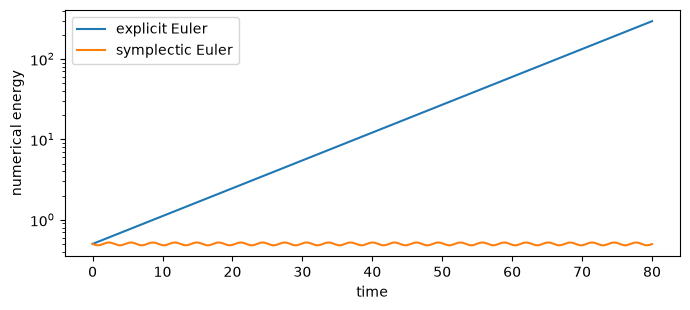

In [2]:
import numpy as np
import matplotlib.pyplot as plt

h, omega, nsteps = 0.08, 1.0, 1000
q1, p1, q2, p2 = 1.0, 0.0, 1.0, 0.0
energies = np.empty((nsteps + 1, 2))
energies[0] = 0.5
for n in range(nsteps):
    q1, p1 = q1+h*p1, p1-h*omega**2*q1
    p2 -= h*omega**2*q2
    q2 += h*p2
    energies[n+1] = [0.5*(p1*p1+omega**2*q1*q1),
                     0.5*(p2*p2+omega**2*q2*q2)]
A = np.array([[1-h*h*omega**2, h], [-h*omega**2, 1.]])
Jmat = np.array([[0., 1.], [-1., 0.]])
assert np.allclose(A.T @ Jmat @ A, Jmat)
assert np.max(np.abs(energies[:, 1]-0.5)) < 0.03
assert energies[-1, 0] > 100*energies[-1, 1]
plt.figure(figsize=(7, 3.2))
plt.semilogy(h*np.arange(nsteps+1), energies[:, 0], label="explicit Euler")
plt.semilogy(h*np.arange(nsteps+1), energies[:, 1], label="symplectic Euler")
plt.xlabel("time"); plt.ylabel("numerical energy"); plt.legend(); plt.tight_layout(); plt.show()

## Memory, stability, and incomplete physics

Reverse differentiation needs the forward states at which step derivatives are evaluated. Storing every state costs memory proportional to the trajectory length. **Checkpointing** stores selected states and recomputes intervening segments during the backward pass, trading additional arithmetic for less memory. Implicit differentiation of converged solves can avoid storing their internal iterations, but it still needs sufficiently accurate primal and adjoint solutions.

Chaotic dynamics amplify small state perturbations. Tangent sensitivities and adjoints can consequently grow rapidly with horizon even when the forward solver is stable. Clipping gradients can help optimization numerically but changes the search direction; it does not solve the scientific problem of estimating a long-time statistical response. Short windows, ensemble objectives, shadowing methods, or objectives based on invariant statistics may be more appropriate, depending on the question.

Contact, switching, and other events require care. If an event occurs at $t_*(\theta)$ defined by $g(y(t_*),\theta)=0$, changing $\theta$ changes both the trajectory and the event time. Holding the event index fixed can omit that contribution. Differentiating the event condition introduces a denominator involving the rate of change of $g$ along the trajectory; near a grazing event that denominator can vanish. Smooth approximations can help optimization, but they replace the original nonsmooth physical model.

A hybrid equation writes $f=f_{\mathrm{known}}+f_\theta^{\mathrm{unknown}}$. Universal differential equations organize such combinations and their sensitivity calculations [@p-rackauckas2020]. Solver-in-the-loop training studies how learned corrections interact with states produced by earlier corrected steps, reducing the gap between isolated training inputs and rollout inputs [@p-um2020]. An unconstrained correction can also compensate for numerical error, missing variables, or biased observations; it should not automatically be interpreted as a new microscopic force law.

NeuralGCM provides a substantial hybrid example: a differentiable atmospheric dynamical core is coupled to learned parameterizations of unresolved processes [@p-kochkov2024]. The reported weather and climate evaluations show that end-to-end training can be useful at scale. Extrapolation to substantially different climates remains a distinct challenge. The same lesson applies in condensed matter and plasma physics: successful fitting within one regime is evidence of a useful effective model, while a claim of new universal physics requires additional tests and theoretical interpretation.

## Implementations to inspect

The [torchdiffeq implementation](https://github.com/rtqichen/torchdiffeq) supports differentiable ODE workflows associated with neural ODEs. The [SciML ecosystem](https://sciml.ai/) develops differential-equation and sensitivity tools, including Julia implementations suited to scientific simulation. For any package, reproduce the scalar adjoint check above before scaling to a complicated model, and distinguish the package's solver tolerances from uncertainty in the physical parameters.

## Exercises and selected answers

1. **Adjoint with observations.** For Euler decay and observations at several steps, derive the adjoint jump from a squared observation error. Implement it and check against finite differences.
2. **Discretization bias.** Derive the exact discrete fitted relaxation rate in the example and expand it through first order in $h$. Compare with the continuous rate.
3. **Implicit equilibrium.** A particle's equilibrium position satisfies $ky+\gamma y^3=F$. Derive $dy/dF$, $dy/dk$, and state when these sensitivities become singular.
4. **Hamiltonian freedom.** Show that $H+C$ gives the same dynamics as $H$. Does $aH$ with $a\ne1$ give the same trajectory as a function of laboratory time?
5. **A structural audit.** Train or fit an oscillator model, then report trajectory error, energy error, time-step refinement, gradient checks, and behavior on an unseen energy shell. Explain why these tests answer different questions.

**Answer to 1.** For $\ell_n=\tfrac12(y_n-y_n^{\mathrm{obs}})^2$, add $y_n-y_n^{\mathrm{obs}}$ to $\lambda_n$ after propagating the future adjoint through the step ending at $n+1$. The parameter gradient still accumulates $-hy_n\lambda_{n+1}$ for each step.

**Answer to 2.** Write $k_c=-\log(y_*)/T$. Then $k_h=(1-e^{-k_ch})/h=k_c-\tfrac12k_c^2h+O(h^2)$. The finite-step model underestimates the continuous rate to compensate for Euler's excess decay.

**Answer to 3.** Implicit differentiation gives $dy/dF=1/(k+3\gamma y^2)$ and $dy/dk=-y/(k+3\gamma y^2)$. A zero denominator marks a loss of local invertibility; near a fold or instability the response can diverge. The physical branch and its stability must be specified.

**Answer to 4.** A constant disappears upon differentiation. Multiplication by $a$ scales the vector field by $a$, so the geometric orbit can be the same but its traversal rate changes. Time-calibrated observations distinguish this scaling.